# Laboratorium 5 — Wprowadzenie do NLP: reprezentacje tekstu i intuicja uwagi

**Cel:** zobaczyć, jak tekst zamienia się w liczby: tokenizacja podsłowna (BPE),
embeddingi (word2vec) i podstawowy mechanizm uwagi. Materiał samowystarczalny —
trenujemy wszystko na małym korpusie polskim, bez pobierania modeli.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [ ]:
!pip -q install tokenizers gensim scikit-learn matplotlib numpy

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import random
np.random.seed(0)
random.seed(5)

## 2. Korpus

Wybrano słowo kostka, zdania utworzono samodzielnie.

In [ ]:
kostka1 = ['Skręcił sobie kostkę, teraz ma spuchniętą.', 'Lubię nosić buty i skarpety za kostki.', 'Zimno jest, a ty z gołymi kostkami chodzisz.', 'Ładna bransoletka na kostkę.',
          'Oni się kopią w kostki, będą mieć sine.', 'Wpadłam w błoto po kostki.', 'Biegał i sobie kostkę skręcił.', 'Widać Ci kostki, podciągnij skarpety.', 'Byłeś na dworze i teraz masz sine kostki.',
          'Dzieci lubią pluskać się w wodzie po kostki, nawet gdy zimno.', 'Uderzyłam się w kostkę, teraz mam spuchniętą.', 'Źle stanął i teraz boli go kostka, pewnie ją skręcił.', 'Zawsze obijam sobie kostki, wiecznie są sine.',
           'Mam skarpety zakrywające kostki.','Zimno mi w kostki, zobacz jakie są sine.', 'Masz ranę na kostce.', 'Buty obcierają mnie w kostki.', 'Mam tatuaż na lewej kostce, ale skarpety zazwyczaj zasłaniają go.',
           'Kasia nie może iść z nami, ma spuchniętą kostkę.', 'Powinaś pójść do lekarza z tą spuchniętą kostką.']
kostka2 = ['Rzucaj tymi kostkami.', 'Moja kostka ma sześć stron.', 'Oczka mojej kostki się wytarły.', 'Nie mam czerwonej kostki, mam tylko zieloną.', 'Nie mogę znaleźć mojej kostki.',
          'Patrz jaka ładna kostka.', 'Ja własnoręcznie maluję swoje kostki do gry.', 'Nigdy nie widziałam jak tyle kostek do gry leży w jednym miejscu.', 'Zgubiłam kostkę do tej gry, pewnie gdzieś leży.', 'Nie możemy grać bez kostek.',
          'Do tej gry w zestawie jest plansza i dwie kostki.', 'Niebieska kostka leży tam gdzie plansza.', 'Wypadły Ci cztery oczka na kostce.', 'Nie rzucaj kostkami, to nie Twoja kolej.', 'Kostka potoczyła się w róg pokoju i dalej tam leży.',
          'On rzucił dwoma kostkami.', 'Ta kostka nie należy do tego samego zestawu co ta plansza.', 'Do tej gry nie potrzebujemy kostki, wystarczy plansza.', 'Znalazłam ostatnio kostkę pod szafką.', 'Nie ma to jak prosta, tradycyjna kostka.']
kostka_bez = ['Ale dzisiaj zimno.', 'Przeczytałam już połowę książki.', 'Ta kartka ma dwie strony.', 'Ala ma kota.', 'On lubi grać w piłkę.', 'Ona kupiła niebieską sukienkę.', 'Dwa koty walczą na ulicy.',
          'Zgubiłam gdzieś mój szal.', 'Widziałam korale czerwone niczym wino.', 'Ich grupa zdobyła szczyt góry.', 'Byłam nad wodą w weekend.', 'Słońce zachodzi na południu.', 'Ostatnie zdanie jest prawdziwe.',
          'Możesz mi wierzyć, obiecuję.', 'Ta książka ma dużo stron.', 'Spotkałam w lesie niedźwiedzia.', 'Mama kupiła dziecku za duże buty.', 'On chce skarpety na święta.', 'Ta droga nigdzie nie prowadzi.', 'To koniec tej historii.']

pary_bpe = [('kostka','kostkach'),('kostkę', 'kostkom'), ('kostki', 'kostko'), ('buty', 'butów'), ('gry', 'grą'), ('czerwone', 'czerwonym'), ('skarpety', 'skarpeta')]

KORPUS = kostka1 + kostka2 + kostka_bez
random.shuffle(KORPUS)
KORPUS = KORPUS * 5
print('Zdań:', len(KORPUS))

Zdań: 300


## 3. Tokenizacja podsłowna (BPE)

Trenujemy tokenizer BPE bezpośrednio na korpusie. Zwróć uwagę, jak polskie formy
fleksyjne dzielą się na rdzeń i końcówki.

In [ ]:
limit_vocab = [100, 300, 500]
wyniki_bpe = {}
formy_widziane = [para[0] for para in pary_bpe]
formy_niewidziane = [para[1] for para in pary_bpe]

def licz_statystyki(formy, tokenizer):
    suma_tok = 0
    liczba_unk = 0
    for w in formy:
        zakodowane = tokenizer.encode(w).tokens
        suma_tok += len(zakodowane)
        if '[UNK]' in zakodowane:
            liczba_unk += 1
        print(f'  {w:15s} -> {zakodowane}')
    return suma_tok / len(formy), liczba_unk

for limit in limit_vocab:
    tok = Tokenizer(models.BPE(unk_token='[UNK]'))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1)
    tok.train_from_iterator(KORPUS, trainer)

    faktyczny_rozmiar = tok.get_vocab_size()
    wyniki_bpe[limit] = {'rozmiar': faktyczny_rozmiar, 'modele': tok}
    print(f'\nLimit słownika: {limit} (Faktyczny rozmiar: {faktyczny_rozmiar})')

    print("\nFormy Widziane")
    srednia_w, unk_w = licz_statystyki(formy_widziane, tok)
    print(f'Średnia: {srednia_w:.2f}, [UNK]: {unk_w}')

    print("\nFormy Niewidziane")
    srednia_nw, unk_nw = licz_statystyki(formy_niewidziane, tok)
    print(f'Średnia: {srednia_nw:.2f}, [UNK]: {unk_nw}')


Limit słownika: 100 (Faktyczny rozmiar: 100)

Formy Widziane
  kostka          -> ['kostk', 'a']
  kostkę          -> ['kostkę']
  kostki          -> ['kostki']
  buty            -> ['b', 'u', 'ty']
  gry             -> ['g', 'ry']
  czerwone        -> ['cz', 'e', 'r', 'wo', 'ne']
  skarpety        -> ['ska', 'r', 'pe', 'ty']
Średnia: 2.57, [UNK]: 0

Formy Niewidziane
  kostkach        -> ['kostk', 'a', 'ch']
  kostkom         -> ['kost', 'ko', 'm']
  kostko          -> ['kost', 'ko']
  butów           -> ['b', 'u', 't', 'ó', 'w']
  grą             -> ['g', 'r', 'ą']
  czerwonym       -> ['cz', 'e', 'r', 'wo', 'n', 'y', 'm']
  skarpeta        -> ['ska', 'r', 'pe', 'ta']
Średnia: 3.86, [UNK]: 0

Limit słownika: 300 (Faktyczny rozmiar: 300)

Formy Widziane
  kostka          -> ['kostka']
  kostkę          -> ['kostkę']
  kostki          -> ['kostki']
  buty            -> ['buty']
  gry             -> ['gry']
  czerwone        -> ['czerwone']
  skarpety        -> ['skarpety']
Średnia: 1.

**Eksperyment:** zmień `vocab_size` (np. 100, 500) i zobacz, jak zmienia się długość podziału.

## 4. Embeddingi word2vec

Uczymy statyczne embeddingi słów. Na tak małym korpusie wyniki są jedynie poglądowe,
ale pokazują ideę: słowa z podobnych kontekstów są blisko siebie.

In [ ]:
w11 = random.sample(kostka1, 12)
w12 = random.sample(kostka2, 4)
korpus_w1 = w11 + w12 + kostka_bez

w21 = random.sample(kostka1, 4)
w22 = random.sample(kostka2, 12)
korpus_w2 = w21 + w22 + kostka_bez

formy_kostki = ['kostkę', 'kostki', 'kostkami', 'kostek', 'kostce', 'kostką']
def ujednolic_kostke(slowo):
    if slowo in formy_kostki:
        return 'kostka'
    return slowo

zdania_w1 = [[ujednolic_kostke(w.lower()) for w in s.replace('.', '').split()] for s in korpus_w1 * 5]
zdania_w2 = [[ujednolic_kostke(w.lower()) for w in s.replace('.', '').split()] for s in korpus_w2 * 5]
w2v_model1 = Word2Vec(zdania_w1, vector_size=50, window=5, min_count=2, sg=1, epochs=200, seed=42, workers=1)
w2v_model2 = Word2Vec(zdania_w2, vector_size=50, window=5, min_count=2, sg=1, epochs=200, seed=42, workers=1)

slowo_badane = 'kostka'
print(f"Najbliżsi sąsiedzi dla słowa '{slowo_badane}':")
if slowo_badane in w2v_model1.wv:
    print(f" Wariant 1 (noga przeważa): {[(s, round(v,2)) for s,v in w2v_model1.wv.most_similar(slowo_badane, topn=5)]}")
if slowo_badane in w2v_model2.wv:
    print(f" Wariant 2 (gra przeważa): {[(s, round(v,2)) for s,v in w2v_model2.wv.most_similar(slowo_badane, topn=5)]}")

Najbliżsi sąsiedzi dla słowa 'kostka':
 Wariant 1 (noga przeważa): [('wpadłam', 0.55), ('oczka', 0.55), ('mojej', 0.55), ('do', 0.53), ('z', 0.53)]
 Wariant 2 (gra przeważa): [('do', 0.6), ('plansza', 0.54), ('leży', 0.54), ('masz', 0.53), ('nie', 0.53)]


## 5. Wizualizacja embeddingów (PCA 2D)

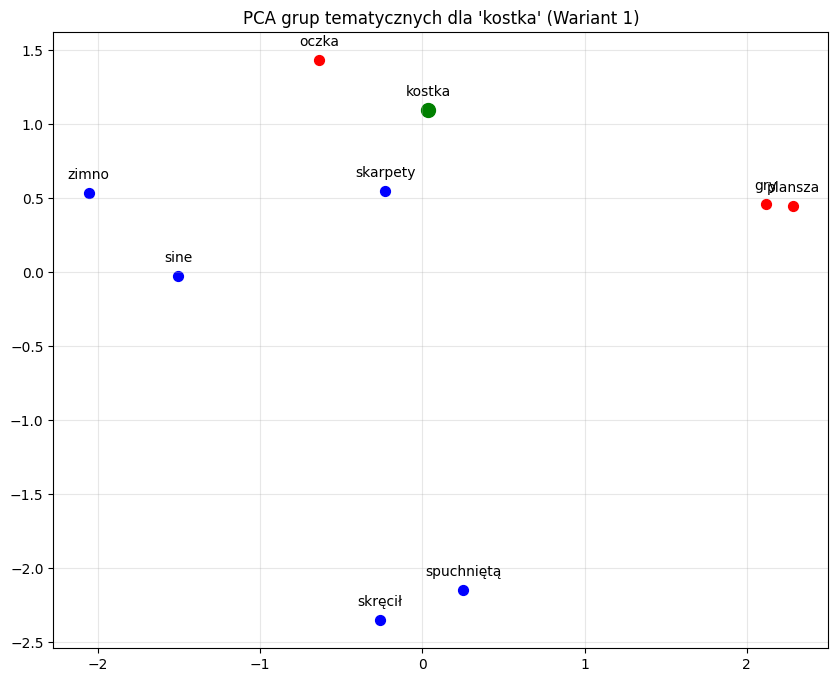

In [ ]:
grupa_noga = ['skręcił', 'zimno', 'skarpety', 'spuchniętą', 'sine']
grupa_gra = ['rzucaj', 'gry', 'plansza', 'leży', 'oczka']

slowa_noga_ob = [w for w in grupa_noga if w in w2v_model1.wv]
slowa_gra_ob = [w for w in grupa_gra if w in w2v_model1.wv]
slowa_do_wykresu = slowa_noga_ob + slowa_gra_ob
if slowo_badane in w2v_model1.wv:
    slowa_do_wykresu.append(slowo_badane)

V = np.stack([w2v_model1.wv[w] for w in slowa_do_wykresu])
XY = PCA(n_components=2, random_state=0).fit_transform(V)

plt.figure(figsize=(10,8))
for w, (x,y) in zip(slowa_do_wykresu, XY):
    color = 'blue' if w in slowa_noga_ob else 'red' if w in slowa_gra_ob else 'green'
    size = 100 if w == slowo_badane else 50
    plt.scatter(x, y, color=color, s=size)
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(0,10), ha='center', fontsize=10)

plt.title(f"PCA grup tematycznych dla '{slowo_badane}' (Wariant 1)")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
print("Średnie podobieństwo cosinusowe w pełnych wymiarach (Wariant 1):")
if len(slowa_noga_ob) > 1 and len(slowa_gra_ob) > 1:
    wektory_noga = np.stack([w2v_model1.wv[w] for w in slowa_noga_ob])
    wektory_gra = np.stack([w2v_model1.wv[w] for w in slowa_gra_ob])

    cos_wewnatrz_b = cosine_similarity(wektory_noga)
    srednia_wewnatrz_b = np.mean(cos_wewnatrz_b[np.triu_indices_from(cos_wewnatrz_b, k=1)])

    cos_wewnatrz_z = cosine_similarity(wektory_gra)
    srednia_wewnatrz_z = np.mean(cos_wewnatrz_z[np.triu_indices_from(cos_wewnatrz_z, k=1)])

    # Cosinus między grupami
    cos_miedzy = cosine_similarity(wektory_noga, wektory_gra)
    srednia_miedzy = np.mean(cos_miedzy)

    print(f" Wewnątrz grupy 'noga': {srednia_wewnatrz_b:.3f}")
    print(f" Wewnątrz grupy 'gra': {srednia_wewnatrz_z:.3f}")
    print(f" Między grupami: {srednia_miedzy:.3f}")
else:
    print("Zbyt mało słów z grup występuje w modelu, by obliczyć rzetelną średnią.")

Średnie podobieństwo cosinusowe w pełnych wymiarach (Wariant 1):
 Wewnątrz grupy 'noga': 0.368
 Wewnątrz grupy 'gra': 0.619
 Między grupami: 0.335
